** **AgriCare AI: Plant Disease Detection**

A CNN-based image classifier that predicts the plant type and disease (or healthy) from a leaf photo.**

**## 2. **Load the Dataset**

The assignment suggests TensorFlow Datasets (TFDS), but the TFDS download failed with HTTP 403 from the source host (Mendeley). I used the PlantVillage dataset from Kaggle instead (color images, 38 classes, about 54,305 images) and downloaded it with `kagglehub`.**

In [2]:
!pip install -q kagglehub

In [3]:
import tensorflow as tf
from tensorflow import keras

In [4]:
import kagglehub

In [5]:
path = kagglehub.dataset_download("abdallahalidev/plantvillage-dataset")
print("Downloaded to:", path)

Using Colab cache for faster access to the 'plantvillage-dataset' dataset.
Downloaded to: /kaggle/input/plantvillage-dataset


**## 3. **Dataset Structure**

The dataset has three folders with the same images in different forms: `color`, `grayscale` and `segmented`. I use `color` because a real user will upload a color photo, and disease colors (yellow, brown, black spots) are important clues.

Inside `color` there is one folder per class, and the folder name is the label (format: `Plant___Disease`):

```
color/
├── Apple___Apple_scab/
├── Apple___healthy/
├── Tomato___Late_blight/
└── ... (38 class folders in total)
```

This cell finds the `color` folder, lists the 38 class names and counts all images. **

In [6]:
import os

color_dir = None
for root,dirs,files in os.walk(path):
  if os.path.basename(root) == 'color':
    color_dir = root
    break

print('Color folder:',color_dir)

classes = sorted(os.listdir(color_dir))
print('Number of Classes:',len(classes))
print(classes[:5])

total= sum(len(os.listdir(os.path.join(color_dir,c)))for c in classes)
print('Total Images:',total)

Color folder: /kaggle/input/plantvillage-dataset/plantvillage dataset/color
Number of Classes: 38
['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueberry___healthy']
Total Images: 54305


**## 4.**Explore the Data**

Count images per class and view one sample image.

**Observations:**
- Smallest class: [class name] with [number] images. Largest class: [class name] with [number] images.
- The classes are imbalanced, so accuracy alone can be misleading. I will also check per-class precision, recall and F1-score.
- Image size: [width x height] pixels.
- The leaf is photographed on a plain background, so this is a laboratory-style dataset.**

  152  Potato___healthy
  275  Apple___Cedar_apple_rust
  360  Peach___healthy
  371  Raspberry___healthy
  373  Tomato___Tomato_mosaic_virus
  423  Grape___healthy
  456  Strawberry___healthy
  513  Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot
  621  Apple___Black_rot
  630  Apple___Apple_scab
  854  Cherry_(including_sour)___healthy
  952  Tomato___Leaf_Mold
  985  Corn_(maize)___Northern_Leaf_Blight
  997  Pepper,_bell___Bacterial_spot
 1000  Potato___Early_blight
 1000  Potato___Late_blight
 1000  Tomato___Early_blight
 1052  Cherry_(including_sour)___Powdery_mildew
 1076  Grape___Leaf_blight_(Isariopsis_Leaf_Spot)
 1109  Strawberry___Leaf_scorch
 1162  Corn_(maize)___healthy
 1180  Grape___Black_rot
 1192  Corn_(maize)___Common_rust_
 1383  Grape___Esca_(Black_Measles)
 1404  Tomato___Target_Spot
 1478  Pepper,_bell___healthy
 1502  Blueberry___healthy
 1591  Tomato___healthy
 1645  Apple___healthy
 1676  Tomato___Spider_mites Two-spotted_spider_mite
 1771  Tomato___Septoria

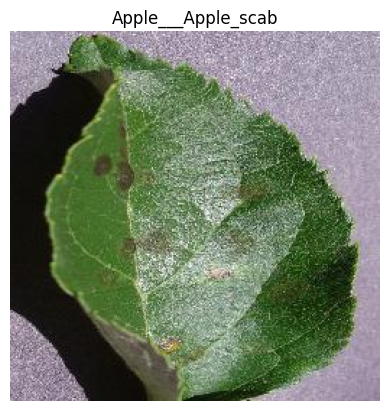

In [7]:
import matplotlib.pyplot as plt
from PIL import Image

counts = {c: len(os.listdir(os.path.join(color_dir,c)))for c in classes}
for c , n in sorted(counts.items(),key=lambda x:x[1]):
  print(f"{n:5d}  {c}")

c = classes[0]
first = os.listdir(os.path.join(color_dir,c))[0]
img = Image.open(os.path.join(color_dir,c,first))
print('Image Size:',img.size)
plt.imshow(img)
plt.title(c)
plt.axis('off')
plt.show()

**## 5. **Build an Image Index**

Create a table (`df`) with the file path of every image and its numeric label (0 to 37). The images are not loaded into memory yet, only their paths are stored.**

In [8]:
import pandas as pd
from sklearn.model_selection import train_test_split

rows = []
for idx,c in enumerate(classes):
  folder = os.path.join(color_dir,c)
  for f in os.listdir(folder):
    if f.lower().endswith(('.jpg','.jpeg','.png')):
      rows.append((os.path.join(folder,f),idx))

df = pd.DataFrame(rows,columns=['path','label'])
print(df.shape)
print(df.head())
print(df.iloc[0,0])


(54305, 2)
                                                path  label
0  /kaggle/input/plantvillage-dataset/plantvillag...      0
1  /kaggle/input/plantvillage-dataset/plantvillag...      0
2  /kaggle/input/plantvillage-dataset/plantvillag...      0
3  /kaggle/input/plantvillage-dataset/plantvillag...      0
4  /kaggle/input/plantvillage-dataset/plantvillag...      0
/kaggle/input/plantvillage-dataset/plantvillage dataset/color/Apple___Apple_scab/5a178d63-372d-48c4-adb8-d616130ba3f0___FREC_Scab 3104.JPG


**## 6. **Train / Validation / Test Split**

Split the data 80% / 10% / 10% using `train_test_split` twice, with `random_state=42` and `stratify` on the label so each class has the same share in every split.

- Train: used to learn the model weights
- Validation: used to monitor training and tune settings
- Test: used only once at the end for the final evaluation**

In [9]:
train_df,temp_df = train_test_split(df,test_size=0.2,random_state=42,stratify=df['label'])

val_df,test_df = train_test_split(temp_df,test_size=0.5,random_state=42,stratify=temp_df['label'])

print('Train:',len(train_df))
print('Val:',len(val_df))
print('Test:',len(test_df))

Train: 43444
Val: 5430
Test: 5431


In [10]:
def share(d):
  return d['label'].value_counts(normalize=True).sort_index()

print('Max farq train vs val:', (share(train_df) - share(val_df)).abs().max())
print('Max farq train vs test:', (share(train_df) - share(test_df)).abs().max())

Max farq train vs val: 0.00013899055586557262
Max farq train vs test: 0.0001590925901497689


In [11]:
classes_names = classes
num_classes = len(classes_names)
print(num_classes)
print(classes_names[0],classes_names[37])

38
Apple___Apple_scab Tomato___healthy


**## 9. Image Settings and Loading Function**

In [12]:
IMG_SIZE = 128
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

def load_image(path, label):
    img_bytes = tf.io.read_file(path)
    img = tf.io.decode_image(img_bytes, channels=3, expand_animations=False)
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
    return img, label

**## 10. Build the Input Pipeline (tf.data)**

In [13]:
def make_dataset(dataframe,training=False):
  ds = tf.data.Dataset.from_tensor_slices(
      (dataframe['path'].values,dataframe['label'].values)
  )
  if training:
    ds = ds.shuffle(len(dataframe),seed=42)
  ds = ds.map(load_image,num_parallel_calls=AUTOTUNE)
  ds = ds.batch(BATCH_SIZE)
  ds = ds.prefetch(AUTOTUNE)
  return ds

train_ds = make_dataset(train_df,training=True)
val_ds = make_dataset(val_df)
test_ds = make_dataset(test_df)

In [14]:
import numpy as np

**## 11. Check One Batch**

In [15]:
for images,labels in train_ds.take(1):
  print('Images Size:',images.shape)
  print("Images dtype:",images.dtype)
  print('labels shape:',labels.shape)
  print('Pixel min/max:',images.numpy().min(),images.numpy().max())

Images Size: (32, 128, 128, 3)
Images dtype: <dtype: 'float32'>
labels shape: (32,)
Pixel min/max: 0.0 249.75


**## 12. Visualize Sample Images from a Batch**

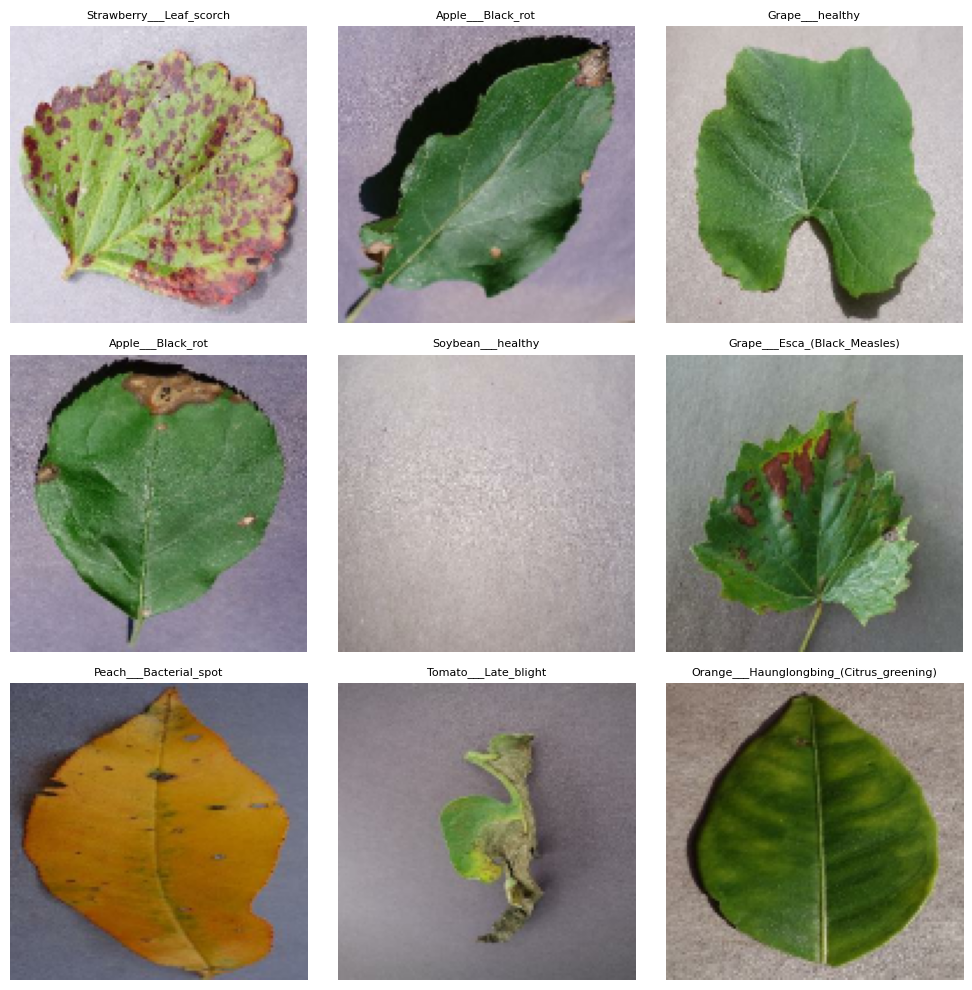

In [16]:
plt.figure(figsize=(10,10))
for i in range(9):
  plt.subplot(3,3,i +1)
  plt.imshow(images[i].numpy().astype('uint8'))
  plt.title(classes_names[labels[i].numpy()], fontsize=8)
  plt.axis('off')
plt.tight_layout()
plt.show()

**## 13. ANN: Understanding Neurons, Weights and Biases**

In [17]:
import numpy as np

x = np.array([2.0, 3.0])        # input (do numbers)
w = np.array([0.5, 0.2])        # weights
b = 1.0                         # bias

z = np.dot(x, w) + b            # 2*0.5 + 3*0.2 + 1 = 2.6
relu = max(0, z)                # ReLU: negative ho to 0, warna wohi
print("z =", z)
print("ReLU output =", relu)

z = 2.6
ReLU output = 2.6


**## 14. Build a Small ANN and Inspect Its Parameters**

In [18]:
from tensorflow import keras
from tensorflow.keras import layers

ann = keras.Sequential([
    #Input layer
    layers.Input(shape=(IMG_SIZE,IMG_SIZE,3)),

    #Hidden layers
    layers.Rescaling(1./255),
    layers.Flatten(),
    layers.Dense(64,activation='relu'),

    #outputlayer
    layers.Dense(num_classes,activation='softmax'),

])

ann.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 49152)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │     3,145,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 38)             │         2,470 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,148,262 (12.01 MB)

 Trainable params: 3,148,262 (12.01 MB)

 Non-trainable params: 0 (0.00 B)

In [19]:
for images,labels in train_ds.take(1):
  proba = ann(images)
  print('Output Shape:',proba.shape)
  print('First Image probabilities:', proba[0].numpy().round(3))
  print("Sum:", proba[0].numpy().sum())
  print("Predicted class:", classes_names[int(tf.argmax(proba[0]))])
  print("Actual class   :", classes_names[int(labels[0])])

Output Shape: (32, 38)
First Image probabilities: [0.041 0.019 0.047 0.02  0.037 0.019 0.06  0.031 0.021 0.014 0.035 0.027
 0.036 0.026 0.038 0.04  0.023 0.036 0.013 0.016 0.034 0.012 0.039 0.013
 0.04  0.027 0.028 0.013 0.019 0.03  0.023 0.018 0.026 0.009 0.016 0.023
 0.01  0.021]
Sum: 1.0
Predicted class: Cherry_(including_sour)___healthy
Actual class   : Tomato___Tomato_Yellow_Leaf_Curl_Virus


**Data Modeling With CNN**

In [21]:
from tensorflow import keras
from tensorflow.keras import layers

cnn = keras.Sequential([
    #input layer
    layers.Input(shape=(IMG_SIZE,IMG_SIZE,3)),
    layers.Rescaling(1./255),

    #hidden layer
    layers.Conv2D(32,(3,3),padding='same',activation='relu'),
    layers.MaxPool2D((2,2)),

    layers.Conv2D(64,(3,3),padding='same',activation='relu'),
    layers.MaxPool2D((2,2)),

    layers.Conv2D(128,(3,3),padding='same',activation='relu'),
    layers.MaxPool2D((2,2)),

    #output layers
    layers.Flatten(),
    layers.Dense(128,activation='relu'),
    layers.Dense(num_classes,activation='softmax'),
])

cnn.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_1 (Rescaling)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │     4,194,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 38)             │         4,902 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,292,582 (16.37 MB)

 Trainable params: 4,292,582 (16.37 MB)

 Non-trainable params: 0 (0.00 B)

In [23]:
for images,labels in train_ds.take(1):
  probs = cnn(images)
  print('Output Shape:',probs.shape)
  print("Sum of first image:", probs[0].numpy().sum())
  print("Predicted:", classes_names[int(tf.argmax(probs[0]))])
  print("Actual   :", classes_names[int(labels[0])])

Output Shape: (32, 38)
Sum of first image: 1.0
Predicted: Soybean___healthy
Actual   : Soybean___healthy


**## 16. Compile the Model
Use the Adam optimizer (learning rate 0.001), sparse categorical cross-entropy loss (labels are integers 0 to 37) and accuracy as the metric.**

In [24]:
cnn.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),loss='sparse_categorical_crossentropy',metrics=['accuracy'])

In [25]:
loss,acc = cnn.evaluate(val_ds.take(20),verbose=0)
print("Loss before training:", round(loss, 3))
print("Accuracy before training:", round(acc, 3))
print("Random guess loss ln(38):", round(float(np.log(38)), 3))
print("Random guess accuracy 1/38:", round(1/38, 3))

Loss before training: 3.619
Accuracy before training: 0.103
Random guess loss ln(38): 3.638
Random guess accuracy 1/38: 0.026


In [26]:
EPOCHS = 5

In [27]:
history = cnn.fit(train_ds,validation_data=val_ds,epochs=EPOCHS)

Epoch 1/5
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 144s 101ms/step - accuracy: 0.7064 - loss: 1.0116 - val_accuracy: 0.8678 - val_loss: 0.4295
Epoch 2/5
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 40s 29ms/step - accuracy: 0.8920 - loss: 0.3389 - val_accuracy: 0.9007 - val_loss: 0.3130
Epoch 3/5
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 40s 29ms/step - accuracy: 0.9369 - loss: 0.1900 - val_accuracy: 0.9055 - val_loss: 0.3127
Epoch 4/5
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 39s 29ms/step - accuracy: 0.9567 - loss: 0.1301 - val_accuracy: 0.9142 - val_loss: 0.2898
Epoch 5/5
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 39s 29ms/step - accuracy: 0.9678 - loss: 0.0974 - val_accuracy: 0.9285 - val_loss: 0.2512


In [30]:
import pandas as pd
hist_df = pd.DataFrame(history.history)
print(hist_df.round(4))
hist_df.to_csv('history_cnn_v1.csv', index=False)

   accuracy    loss  val_accuracy  val_loss
0    0.7064  1.0116        0.8678    0.4295
1    0.8920  0.3389        0.9007    0.3130
2    0.9369  0.1900        0.9055    0.3127
3    0.9567  0.1301        0.9142    0.2898
4    0.9678  0.0974        0.9285    0.2512


**Plotting MOdel Loss & Accuracy On Training & Validation Data**

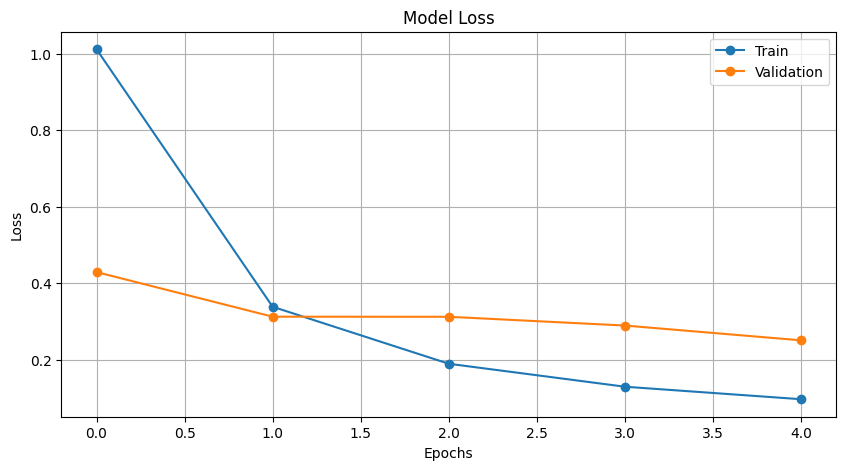

In [42]:
plt.figure(figsize=(10,5))
plt.grid(True)
plt.title('Model Loss')
plt.plot(history.history['loss'], marker='o')
plt.plot(history.history['val_loss'], marker='o')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend(["Train","Validation"])
plt.show()

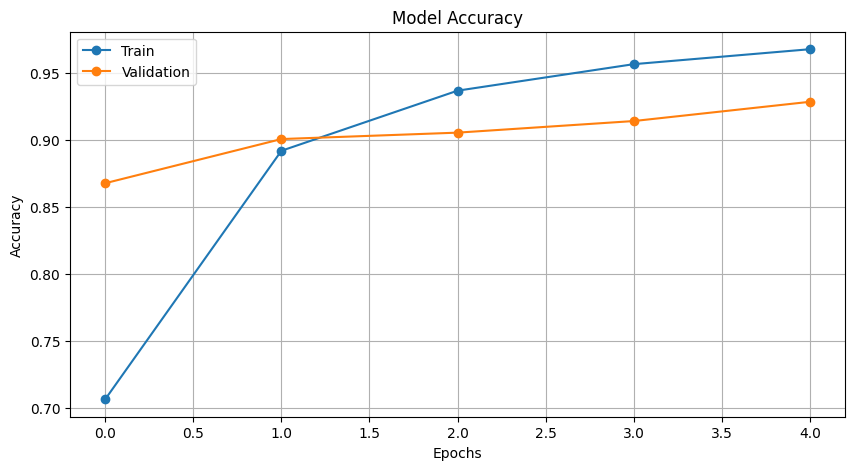

In [40]:
plt.figure(figsize=(10,5))
plt.grid(True)
plt.title('Model Accuracy')
plt.plot(history.history['accuracy'], marker='o')
plt.plot(history.history['val_accuracy'], marker='o')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend(["Train","Validation"])
plt.show()



In [43]:
print("Majority-class baseline:", round(max(counts.values()) / total, 3))

Majority-class baseline: 0.101


**Saving The Model in "keras" File**

In [31]:
cnn.save('cnn_v1.keras')

**## 20. Reduce Overfitting: Augmentation, Dropout and Early Stopping
Train a second model (`cnn_v2`) with data augmentation, a Dropout layer (0.5) and early stopping, then compare it with the first model.**

In [46]:
from sklearn.utils.validation import validate_data
data_augmentation = keras.Sequential([
    layers.RandomFlip('horizontal_and_vertical'),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1),
  ],name='augmentation')

cnn_v2 = keras.Sequential([
    layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
    data_augmentation,
    layers.Rescaling(1./255),

    layers.Conv2D(32, (3, 3), padding='same', activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), padding='same', activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(128, (3, 3), padding='same', activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dropout(0.5),
    layers.Dense(128, activation='relu'),
    layers.Dense(num_classes, activation='softmax'),
], name="cnn_v2")

cnn_v2.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)


early_stop = keras.callbacks.EarlyStopping(monitor='val_loss',patience=3,restore_best_weights=True)

history_v2 = cnn_v2.fit(train_ds,validation_data=val_ds,epochs=15,callbacks=[early_stop])

Epoch 1/15
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 54s 34ms/step - accuracy: 0.6216 - loss: 1.3125 - val_accuracy: 0.7133 - val_loss: 0.9310
Epoch 2/15
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 49s 36ms/step - accuracy: 0.8114 - loss: 0.5958 - val_accuracy: 0.7899 - val_loss: 0.6732
Epoch 3/15
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 105s 53ms/step - accuracy: 0.8667 - loss: 0.4197 - val_accuracy: 0.8768 - val_loss: 0.3748
Epoch 4/15
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 67s 49ms/step - accuracy: 0.8894 - loss: 0.3394 - val_accuracy: 0.9024 - val_loss: 0.2936
Epoch 5/15
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 60s 33ms/step - accuracy: 0.9068 - loss: 0.2866 - val_accuracy: 0.9122 - val_loss: 0.2677
Epoch 6/15
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 45s 33ms/step - accuracy: 0.9175 - loss: 0.2521 - val_accuracy: 0.9236 - val_loss: 0.2169
Epoch 7/15
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 47s 34ms/step - accuracy: 0.9222 - loss: 0.2341 - val_accuracy: 0.9352 - val_loss: 0.2056
Epoch 8/15
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 48s 35ms/step - accuracy: 0.9319 

In [49]:
import pandas as pd

cnn_v2.save('cnn_v2.keras')
pd.DataFrame(history_v2.history).to_csv('history_cnn_v2.csv',index=False)
print(pd.DataFrame(history_v2.history).round(4))

    accuracy    loss  val_accuracy  val_loss
0     0.6216  1.3125        0.7133    0.9310
1     0.8114  0.5958        0.7899    0.6732
2     0.8667  0.4197        0.8768    0.3748
3     0.8894  0.3394        0.9024    0.2936
4     0.9068  0.2866        0.9122    0.2677
5     0.9175  0.2521        0.9236    0.2169
6     0.9222  0.2341        0.9352    0.2056
7     0.9319  0.2064        0.9324    0.2069
8     0.9357  0.1957        0.9490    0.1639
9     0.9397  0.1835        0.9440    0.1715
10    0.9434  0.1709        0.9545    0.1441
11    0.9474  0.1570        0.9280    0.2259
12    0.9493  0.1530        0.9460    0.1532
13    0.9504  0.1480        0.9562    0.1327
14    0.9507  0.1464        0.9617    0.1141


**Plotting MOdel Loss & Accuracy On Training & Validation Data**

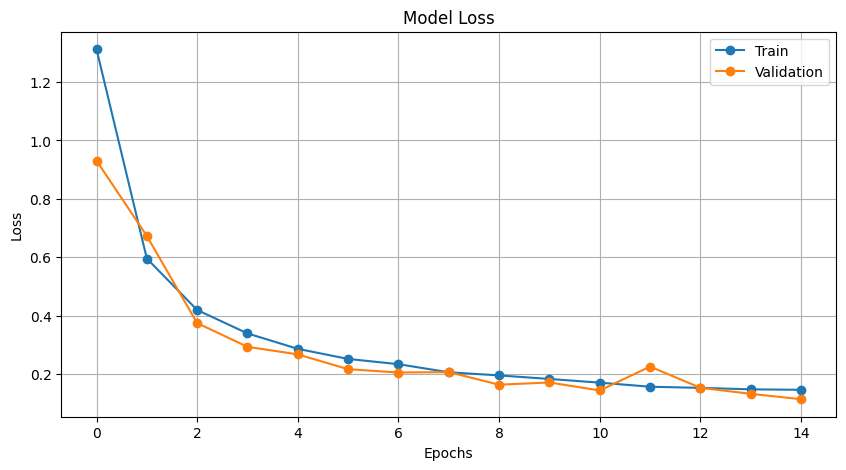

In [50]:
plt.figure(figsize=(10,5))
plt.grid(True)
plt.title('Model Loss')
plt.plot(history_v2.history['loss'], marker='o')
plt.plot(history_v2.history['val_loss'], marker='o')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend(["Train","Validation"])
plt.show()

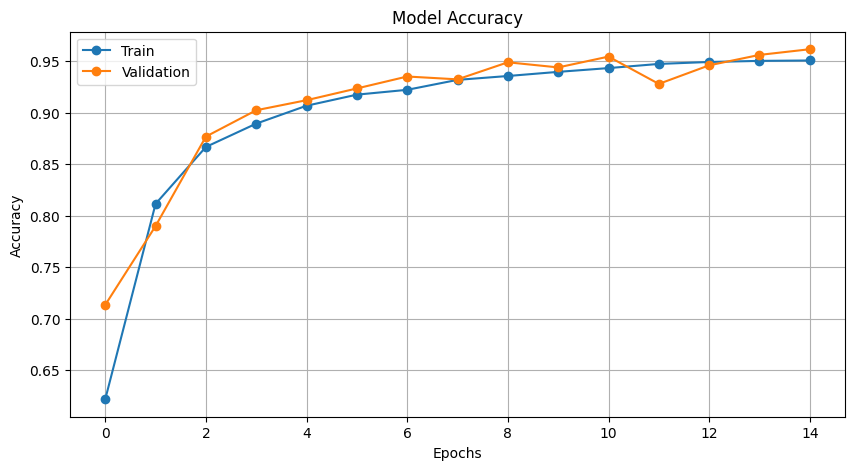

In [51]:
plt.figure(figsize=(10,5))
plt.grid(True)
plt.title('Model Accuracy')
plt.plot(history_v2.history['accuracy'], marker='o')
plt.plot(history_v2.history['val_accuracy'], marker='o')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend(["Train","Validation"])
plt.show()



**## 22. Error Analysis on the Validation Set

Use the validation set (not the test set) to compute per-class precision, recall and F1, a confusion matrix, and the most common confusions.**

****Findings:** The weakest classes are [..] (F1 = [..]). The most common confusion is [class A] predicted as [class B] ([n] times), likely because [reason after viewing the images].**

In [52]:
from sklearn.metrics import classification_report, confusion_matrix

y_true = val_df['label'].values
y_prob = cnn_v2.predict(val_ds)
y_pred = np.argmax(y_prob, axis=1)

print(y_true.shape, y_pred.shape)
print("Accuracy:", (y_true == y_pred).mean())

170/170 ━━━━━━━━━━━━━━━━━━━━ 6s 33ms/step
(5430,) (5430,)
Accuracy: 0.961694290976059


In [54]:
print(classification_report(y_true, y_pred, target_names=classes_names, digits=3))

                                                    precision    recall  f1-score   support

                                Apple___Apple_scab      0.967     0.937     0.952        63
                                 Apple___Black_rot      0.884     0.984     0.931        62
                          Apple___Cedar_apple_rust      0.963     0.929     0.945        28
                                   Apple___healthy      0.958     0.982     0.970       164
                               Blueberry___healthy      0.987     0.993     0.990       150
          Cherry_(including_sour)___Powdery_mildew      0.990     0.990     0.990       105
                 Cherry_(including_sour)___healthy      1.000     1.000     1.000        86
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot      0.710     0.942     0.810        52
                       Corn_(maize)___Common_rust_      1.000     1.000     1.000       119
               Corn_(maize)___Northern_Leaf_Blight      0.963     0.788     0.8

In [56]:
from sklearn.metrics import precision_recall_fscore_support

p, r, f, s = precision_recall_fscore_support(y_true, y_pred, labels=range(num_classes), zero_division=0)
report_df = pd.DataFrame({'class': classes_names, 'precision': p, 'recall': r, 'f1': f, 'support': s})
print(report_df.sort_values('f1').head(8).round(3))

                                                class  precision  recall  \
22                                   Potato___healthy      0.591   0.867   
7   Corn_(maize)___Cercospora_leaf_spot Gray_leaf_...      0.710   0.942   
17                                    Peach___healthy      1.000   0.750   
9                 Corn_(maize)___Northern_Leaf_Blight      0.963   0.788   
29                              Tomato___Early_blight      0.924   0.850   
11                                  Grape___Black_rot      0.936   0.864   
23                                Raspberry___healthy      0.822   1.000   
34                               Tomato___Target_Spot      0.865   0.957   

       f1  support  
22  0.703       15  
7   0.810       52  
17  0.857       36  
9   0.867       99  
29  0.885      100  
11  0.899      118  
23  0.902       37  
34  0.908      140  


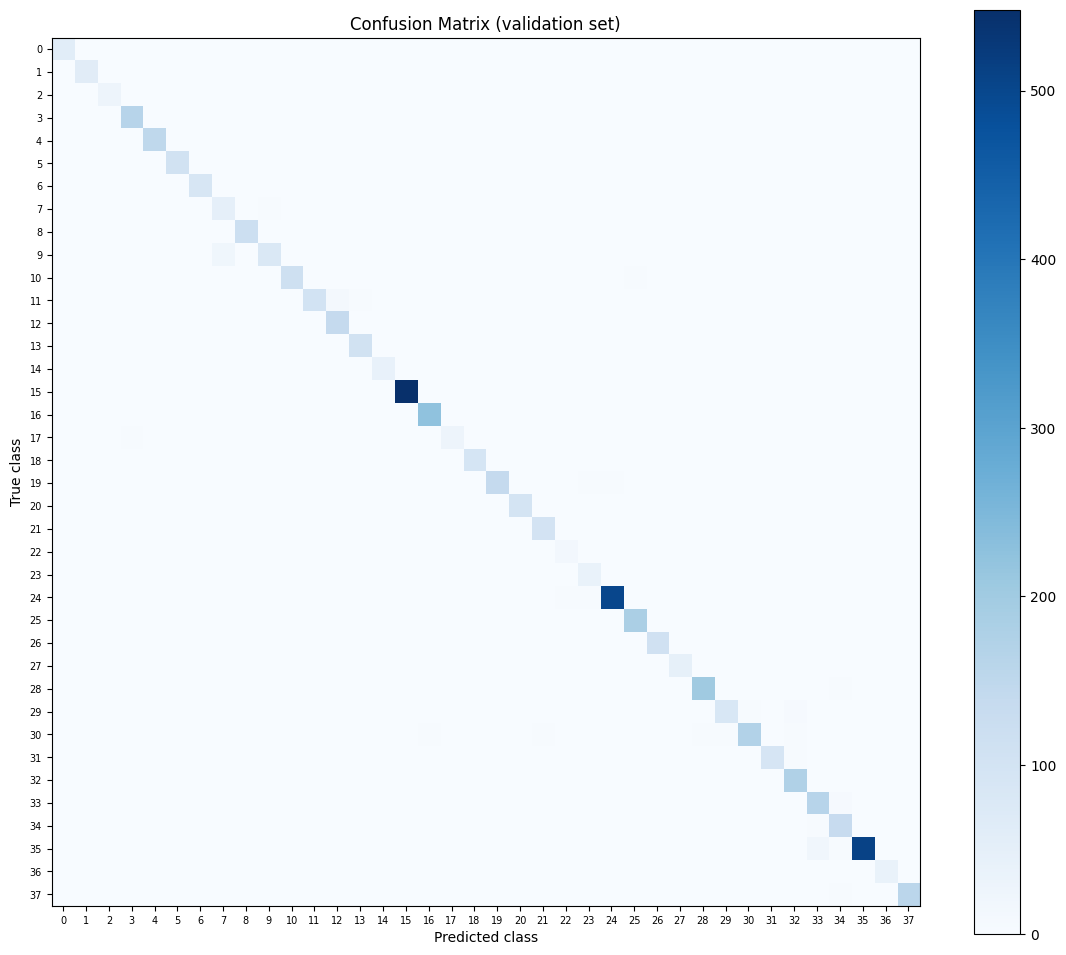

In [57]:
cm = confusion_matrix(y_true, y_pred, labels=range(num_classes))

plt.figure(figsize=(14, 12))
plt.imshow(cm, cmap='Blues')
plt.colorbar()
plt.title('Confusion Matrix (validation set)')
plt.xlabel('Predicted class')
plt.ylabel('True class')
plt.xticks(range(num_classes), range(num_classes), fontsize=7)
plt.yticks(range(num_classes), range(num_classes), fontsize=7)
plt.show()

In [58]:
for i, name in enumerate(classes_names):
    print(i, name)

0 Apple___Apple_scab
1 Apple___Black_rot
2 Apple___Cedar_apple_rust
3 Apple___healthy
4 Blueberry___healthy
5 Cherry_(including_sour)___Powdery_mildew
6 Cherry_(including_sour)___healthy
7 Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot
8 Corn_(maize)___Common_rust_
9 Corn_(maize)___Northern_Leaf_Blight
10 Corn_(maize)___healthy
11 Grape___Black_rot
12 Grape___Esca_(Black_Measles)
13 Grape___Leaf_blight_(Isariopsis_Leaf_Spot)
14 Grape___healthy
15 Orange___Haunglongbing_(Citrus_greening)
16 Peach___Bacterial_spot
17 Peach___healthy
18 Pepper,_bell___Bacterial_spot
19 Pepper,_bell___healthy
20 Potato___Early_blight
21 Potato___Late_blight
22 Potato___healthy
23 Raspberry___healthy
24 Soybean___healthy
25 Squash___Powdery_mildew
26 Strawberry___Leaf_scorch
27 Strawberry___healthy
28 Tomato___Bacterial_spot
29 Tomato___Early_blight
30 Tomato___Late_blight
31 Tomato___Leaf_Mold
32 Tomato___Septoria_leaf_spot
33 Tomato___Spider_mites Two-spotted_spider_mite
34 Tomato___Target_Spot
35 Tom

In [60]:
cm_off = cm.copy()
np.fill_diagonal(cm_off, 0)

top = np.argsort(cm_off.ravel())[::-1][:10]
for idx in top:
    t, pr = divmod(idx, num_classes)
    if cm_off[t, pr] > 0:
        print(f"{cm_off[t, pr]:3d} times: {classes_names[t]}  ->  {classes_names[pr]}")

 20 times: Corn_(maize)___Northern_Leaf_Blight  ->  Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot
 19 times: Tomato___Tomato_Yellow_Leaf_Curl_Virus  ->  Tomato___Spider_mites Two-spotted_spider_mite
 11 times: Grape___Black_rot  ->  Grape___Esca_(Black_Measles)
  6 times: Tomato___Spider_mites Two-spotted_spider_mite  ->  Tomato___Target_Spot
  6 times: Tomato___Early_blight  ->  Tomato___Septoria_leaf_spot
  4 times: Soybean___healthy  ->  Potato___healthy
  4 times: Tomato___healthy  ->  Tomato___Target_Spot
  4 times: Tomato___Tomato_Yellow_Leaf_Curl_Virus  ->  Tomato___Target_Spot
  4 times: Grape___Black_rot  ->  Grape___Leaf_blight_(Isariopsis_Leaf_Spot)
  4 times: Corn_(maize)___healthy  ->  Squash___Powdery_mildew


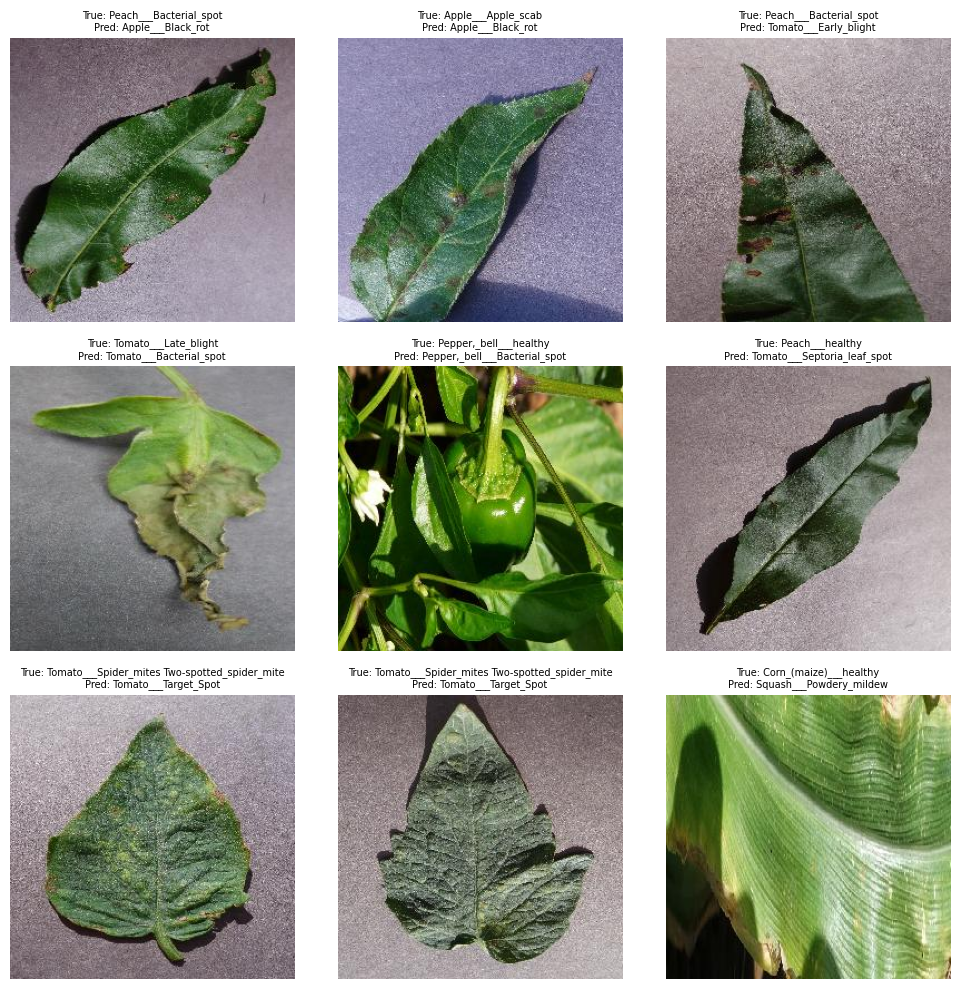

In [62]:
wrong = np.where(y_true != y_pred)[0]
plt.figure(figsize=(10, 10))
for k, i in enumerate(wrong[:9]):
    img = Image.open(val_df.iloc[i]['path']).convert('RGB')
    plt.subplot(3, 3, k + 1)
    plt.imshow(img)
    plt.title(f"True: {classes_names[y_true[i]]}\nPred: {classes_names[y_pred[i]]}", fontsize=7)
    plt.axis('off')
plt.tight_layout()
plt.show()

**## 23. Transfer Learning with MobileNetV2
Use MobileNetV2 pre-trained on ImageNet as a frozen feature extractor, add a new classification head (Global Average Pooling, Dropout, Dense 38 softmax) and train only the head. Compare its validation results with the CNNs built from scratch.**

In [63]:
base = keras.applications.MobileNetV2(
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
    include_top=False,
    weights='imagenet'
)
base.trainable = False

inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = data_augmentation(inputs)
x = layers.Rescaling(1./127.5, offset=-1)(x)
x = base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(num_classes, activation='softmax')(x)

mobilenet = keras.Model(inputs, outputs, name="mobilenet_tl")

mobilenet.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

mobilenet.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "mobilenet_tl"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_7 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_4 (Rescaling)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_128            │ (None, 4, 4, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 38)             │        48,678 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,306,662 (8.80 MB)

 Trainable params: 48,678 (190.15 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

**## 23. Transfer Learning with MobileNetV2 (Frozen Base)
**Result:** With a frozen base, MobileNetV2 reached 91.93% validation accuracy (val loss 0.255) and early stopping ended training after 6 epochs, restoring the epoch-3 weights. This is lower than my CNN with augmentation (96.17%). Likely reasons: ImageNet features are not tuned to leaf diseases, the images are resized to 128x128 while MobileNetV2 was trained at 224x224, and the small head has limited capacity.**

In [64]:
early_stop = keras.callbacks.EarlyStopping(
    monitor='val_loss', patience=3, restore_best_weights=True
)

history_tl = mobilenet.fit(
    train_ds,
    validation_data=val_ds,
    epochs=8,
    callbacks=[early_stop]
)

mobilenet.save('mobilenet_tl.keras')
pd.DataFrame(history_tl.history).to_csv('history_mobilenet.csv', index=False)
print(pd.DataFrame(history_tl.history).round(4))

Epoch 1/8
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 56s 35ms/step - accuracy: 0.8064 - loss: 0.6566 - val_accuracy: 0.8899 - val_loss: 0.3659
Epoch 2/8
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 82s 36ms/step - accuracy: 0.8884 - loss: 0.3488 - val_accuracy: 0.9020 - val_loss: 0.3011
Epoch 3/8
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 46s 34ms/step - accuracy: 0.8972 - loss: 0.3183 - val_accuracy: 0.9193 - val_loss: 0.2551
Epoch 4/8
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 82s 34ms/step - accuracy: 0.9026 - loss: 0.3000 - val_accuracy: 0.9162 - val_loss: 0.2669
Epoch 5/8
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 45s 33ms/step - accuracy: 0.9072 - loss: 0.2873 - val_accuracy: 0.9168 - val_loss: 0.2585
Epoch 6/8
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 46s 33ms/step - accuracy: 0.9095 - loss: 0.2802 - val_accuracy: 0.9122 - val_loss: 0.2790
   accuracy    loss  val_accuracy  val_loss
0    0.8064  0.6566        0.8899    0.3659
1    0.8884  0.3488        0.9020    0.3011
2    0.8972  0.3183        0.9193    0.2551
3    0.9026  0.3000        0.9162    0

**## 24. Fine-Tune the Top Layers of MobileNetV2
Unfreeze the last 30 layers of the base model and train with a very small learning rate (1e-5) to adapt the pre-trained features to leaf images.**

In [65]:
base.trainable = True
for layer in base.layers[:-30]:
    layer.trainable = False

mobilenet.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

early_stop_ft = keras.callbacks.EarlyStopping(
    monitor='val_loss', patience=3, restore_best_weights=True
)

history_ft = mobilenet.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    callbacks=[early_stop_ft]
)

mobilenet.save('mobilenet_ft.keras')
pd.DataFrame(history_ft.history).to_csv('history_mobilenet_ft.csv', index=False)
print(pd.DataFrame(history_ft.history).round(4))

Epoch 1/5
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 77s 48ms/step - accuracy: 0.8044 - loss: 0.7644 - val_accuracy: 0.9136 - val_loss: 0.2670
Epoch 2/5
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 61s 45ms/step - accuracy: 0.8911 - loss: 0.3499 - val_accuracy: 0.9265 - val_loss: 0.2294
Epoch 3/5
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 78s 42ms/step - accuracy: 0.9122 - loss: 0.2770 - val_accuracy: 0.9335 - val_loss: 0.2096
Epoch 4/5
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 58s 42ms/step - accuracy: 0.9231 - loss: 0.2390 - val_accuracy: 0.9466 - val_loss: 0.1702
Epoch 5/5
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 58s 42ms/step - accuracy: 0.9315 - loss: 0.2076 - val_accuracy: 0.9479 - val_loss: 0.1617
   accuracy    loss  val_accuracy  val_loss
0    0.8044  0.7644        0.9136    0.2670
1    0.8911  0.3499        0.9265    0.2294
2    0.9122  0.2770        0.9335    0.2096
3    0.9231  0.2390        0.9466    0.1702
4    0.9315  0.2076        0.9479    0.1617


In [66]:
history_ft2 = mobilenet.fit(
    train_ds,
    validation_data=val_ds,
    epochs=8,
    callbacks=[early_stop_ft]
)

mobilenet.save('mobilenet_ft2.keras')
print(pd.DataFrame(history_ft2.history).round(4))

Epoch 1/8
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 60s 44ms/step - accuracy: 0.9394 - loss: 0.1858 - val_accuracy: 0.9529 - val_loss: 0.1456
Epoch 2/8
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 58s 42ms/step - accuracy: 0.9440 - loss: 0.1687 - val_accuracy: 0.9551 - val_loss: 0.1412
Epoch 3/8
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 58s 43ms/step - accuracy: 0.9482 - loss: 0.1523 - val_accuracy: 0.9569 - val_loss: 0.1320
Epoch 4/8
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 58s 43ms/step - accuracy: 0.9523 - loss: 0.1387 - val_accuracy: 0.9575 - val_loss: 0.1290
Epoch 5/8
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 58s 43ms/step - accuracy: 0.9570 - loss: 0.1315 - val_accuracy: 0.9624 - val_loss: 0.1157
Epoch 6/8
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 58s 43ms/step - accuracy: 0.9597 - loss: 0.1217 - val_accuracy: 0.9619 - val_loss: 0.1145
Epoch 7/8
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 58s 43ms/step - accuracy: 0.9598 - loss: 0.1146 - val_accuracy: 0.9632 - val_loss: 0.1105
Epoch 8/8
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 82s 43ms/step - accuracy: 0.9624 - loss: 0

**Final Model save**

In [67]:
mobilenet.save('final_model.keras')
final_model = mobilenet

In [69]:
from sklearn.metrics import classification_report, confusion_matrix, precision_recall_fscore_support

y_true = val_df['label'].values
y_prob = final_model.predict(val_ds)
y_pred = np.argmax(y_prob, axis=1)
print("Validation accuracy:", round((y_true == y_pred).mean(), 4))

print(classification_report(y_true, y_pred, target_names=classes_names, digits=3))

p, r, f, s = precision_recall_fscore_support(
    y_true, y_pred, labels=range(num_classes), zero_division=0)
report_df = pd.DataFrame({'class': classes_names, 'precision': p,
                          'recall': r, 'f1': f, 'support': s})
print(report_df.sort_values('f1').head(8).round(3))

cm = confusion_matrix(y_true, y_pred, labels=range(num_classes))
cm_off = cm.copy()
np.fill_diagonal(cm_off, 0)
top = np.argsort(cm_off.ravel())[::-1][:8]
for idx in top:
    t, pr = divmod(idx, num_classes)
    if cm_off[t, pr] > 0:
        print(f"{cm_off[t, pr]:3d} times: {classes_names[t]} -> {classes_names[pr]}")

170/170 ━━━━━━━━━━━━━━━━━━━━ 7s 44ms/step
Validation accuracy: 0.9659
                                                    precision    recall  f1-score   support

                                Apple___Apple_scab      0.951     0.921     0.935        63
                                 Apple___Black_rot      0.969     1.000     0.984        62
                          Apple___Cedar_apple_rust      1.000     1.000     1.000        28
                                   Apple___healthy      0.970     1.000     0.985       164
                               Blueberry___healthy      1.000     1.000     1.000       150
          Cherry_(including_sour)___Powdery_mildew      1.000     0.962     0.981       105
                 Cherry_(including_sour)___healthy      0.966     1.000     0.983        86
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot      0.915     0.827     0.869        52
                       Corn_(maize)___Common_rust_      1.000     1.000     1.000       119
         

**## 27. Final Evaluation on the Test Set
The test set was used only once, with the final model (fine-tuned MobileNetV2). Test accuracy: [..], test loss: [..], macro F1: [..].**

In [70]:
test_loss,test_acc = final_model.evaluate(test_ds)
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_loss:.4f}")

y_true_t = test_df['label'].values
y_pred_t = np.argmax(final_model.predict(test_ds), axis=1)


print(classification_report(y_true_t, y_pred_t, target_names=classes_names, digits=3))

170/170 ━━━━━━━━━━━━━━━━━━━━ 17s 99ms/step - accuracy: 0.9693 - loss: 0.0984
Test Loss: 0.0984
Test Accuracy: 0.0984
170/170 ━━━━━━━━━━━━━━━━━━━━ 5s 29ms/step
                                                    precision    recall  f1-score   support

                                Apple___Apple_scab      0.908     0.937     0.922        63
                                 Apple___Black_rot      1.000     0.984     0.992        62
                          Apple___Cedar_apple_rust      0.963     0.963     0.963        27
                                   Apple___healthy      0.994     0.994     0.994       165
                               Blueberry___healthy      0.993     1.000     0.997       150
          Cherry_(including_sour)___Powdery_mildew      1.000     0.962     0.981       105
                 Cherry_(including_sour)___healthy      0.988     0.988     0.988        85
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot      0.852     0.902     0.876        51
            

Saving download.png to download.png
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step


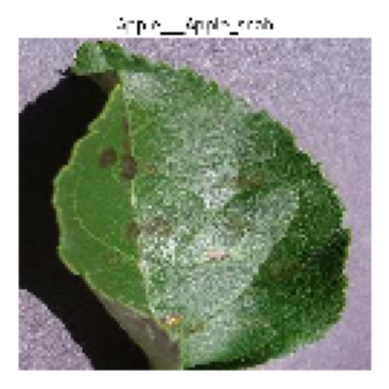

 99.5%  Apple___Apple_scab
  0.2%  Peach___Bacterial_spot
  0.1%  Tomato___healthy


In [72]:
from google.colab import files
uploaded = files.upload()
fname = list(uploaded.keys())[0]

img = keras.utils.load_img(fname, target_size=(IMG_SIZE, IMG_SIZE))
arr = np.expand_dims(keras.utils.img_to_array(img), 0)

probs = final_model.predict(arr)[0]
top3 = np.argsort(probs)[::-1][:3]

plt.imshow(img); plt.axis('off'); plt.show()
for i in top3:
    print(f"{probs[i]*100:5.1f}%  {classes_names[i]}")

if probs[top3[0]] < 0.60:
    print("Low confidence: result may not be reliable.")

**Save Load& Verify**

In [74]:
final_model.save('final_model.keras')

import json
with open('class_names.json', 'w') as f:
    json.dump(classes_names, f)

loaded = keras.models.load_model('final_model.keras')
xb, _ = next(iter(test_ds))
print("Same predictions:", np.allclose(final_model.predict(xb), loaded.predict(xb), atol=1e-5))

import keras
print("TensorFlow:", tf.__version__, "| Keras:", keras.__version__)

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
Same predictions: True
TensorFlow: 2.21.0 | Keras: 3.13.2
